# **1. Import library dan upload dataset**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()

Saving 3TIB_01_DataAkademikMahasiswa.xlsx to 3TIB_01_DataAkademikMahasiswa.xlsx


# **2. Membaca file Excel**

In [ ]:
df = pd.read_excel('3TIB_01_DataAkademikMahasiswa.xlsx')

df.head()

,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [ ]:
print("Jumlah observasi :", df.shape[0])
print("Jumlah variabel  :", df.shape[1])

Jumlah observasi : 4424
Jumlah variabel  : 37


# **3. Memilih tiga variabel penelitian**

In [ ]:
col_enrolled = 'Curricular units 1st sem (enrolled)'
col_approved = 'Curricular units 1st sem (approved)'
col_grade = 'Curricular units 1st sem (grade)'

data = df[
    [col_enrolled, col_approved, col_grade]
].copy()

data.head()

,Curricular units 1st sem (enrolled),Curricular units 1st sem (approved),Curricular units 1st sem (grade)
0,0,0,0.000000
1,6,6,14.000000
2,6,0,0.000000
3,6,6,13.428571
4,6,5,12.333333


In [ ]:
print(data.dtypes)

Curricular units 1st sem (enrolled)      int64
Curricular units 1st sem (approved)      int64
Curricular units 1st sem (grade)       float64
dtype: object


In [ ]:
print("MISSING VALUE")
print(data.isnull().sum())

MISSING VALUE
Curricular units 1st sem (enrolled)    0
Curricular units 1st sem (approved)    0
Curricular units 1st sem (grade)       0
dtype: int64


# **4. Cek calon outlier dengan IQR**

In [ ]:
kolom = [
    col_enrolled,
    col_approved,
    col_grade
]

for k in kolom:
    Q1 = data[k].quantile(0.25)
    Q3 = data[k].quantile(0.75)
    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    outlier = data[
        (data[k] < batas_bawah) |
        (data[k] > batas_atas)
    ]

    print("=" * 60)
    print(k)
    print("Q1                   :", Q1)
    print("Q3                   :", Q3)
    print("IQR                  :", IQR)
    print("Batas bawah          :", batas_bawah)
    print("Batas atas           :", batas_atas)
    print("Jumlah calon outlier :", len(outlier))

Curricular units 1st sem (enrolled)
Q1                   : 5.0
Q3                   : 7.0
IQR                  : 2.0
Batas bawah          : 2.0
Batas atas           : 10.0
Jumlah calon outlier : 424
Curricular units 1st sem (approved)
Q1                   : 3.0
Q3                   : 6.0
IQR                  : 3.0
Batas bawah          : -1.5
Batas atas           : 10.5
Jumlah calon outlier : 180
Curricular units 1st sem (grade)
Q1                   : 11.0
Q3                   : 13.4
IQR                  : 2.4000000000000004
Batas bawah          : 7.3999999999999995
Batas atas           : 17.0
Jumlah calon outlier : 726


# **5. Statistika Deskriptif**

In [ ]:
def statistik_deskriptif(series):
    return pd.Series({
        'Jumlah Data': series.count(),
        'Mean': series.mean(),
        'Median': series.median(),
        'Modus': series.mode().iloc[0],
        'Minimum': series.min(),
        'Maksimum': series.max(),
        'Q1': series.quantile(0.25),
        'Q3': series.quantile(0.75),
        'Range': series.max() - series.min(),
        'Variance': series.var(),
        'Standar Deviasi': series.std(),
        'Standard Error': series.sem(),
        'Skewness': series.skew(),
        'Kurtosis': series.kurt()
    })

In [ ]:
hasil_deskriptif = pd.DataFrame({
    'Enrolled': statistik_deskriptif(data[col_enrolled]),
    'Approved': statistik_deskriptif(data[col_approved]),
    'Grade': statistik_deskriptif(data[col_grade])
})

hasil_deskriptif.round(3)

,Enrolled,Approved,Grade
Jumlah Data,4424.000,4424.000,4424.000
Mean,6.271,4.707,10.641
Median,6.000,5.000,12.286
Modus,6.000,6.000,0.000
Minimum,0.000,0.000,0.000
Maksimum,26.000,26.000,18.875
Q1,5.000,3.000,11.000
Q3,7.000,6.000,13.400
Range,26.000,26.000,18.875
Variance,6.151,9.574,23.461


# **6. Menjawab Rumusan Masalah 1: Beban Studi**

In [ ]:
print("STATISTIKA DESKRIPTIF BEBAN STUDI - ENROLLED")
print("=" * 55)

print("Jumlah Data       :", data[col_enrolled].count())
print("Mean              :", round(data[col_enrolled].mean(), 3))
print("Median            :", round(data[col_enrolled].median(), 3))
print("Modus             :", data[col_enrolled].mode().iloc[0])
print("Minimum           :", data[col_enrolled].min())
print("Maksimum          :", data[col_enrolled].max())
print("Q1                :", data[col_enrolled].quantile(0.25))
print("Q3                :", data[col_enrolled].quantile(0.75))
print("Range             :", data[col_enrolled].max() - data[col_enrolled].min())
print("Variance          :", round(data[col_enrolled].var(), 3))
print("Standar Deviasi   :", round(data[col_enrolled].std(), 3))
print("Standard Error    :", round(data[col_enrolled].sem(), 3))
print("Skewness          :", round(data[col_enrolled].skew(), 3))
print("Kurtosis          :", round(data[col_enrolled].kurt(), 3))

STATISTIKA DESKRIPTIF BEBAN STUDI - ENROLLED
Jumlah Data       : 4424
Mean              : 6.271
Median            : 6.0
Modus             : 6
Minimum           : 0
Maksimum          : 26
Q1                : 5.0
Q3                : 7.0
Range             : 26
Variance          : 6.151
Standar Deviasi   : 2.48
Standard Error    : 0.037
Skewness          : 1.619
Kurtosis          : 8.938


# **7. Menjawab Rumusan Masalah 2: Prestasi Akademik**

In [ ]:
print("STATISTIKA DESKRIPTIF PRESTASI AKADEMIK")
print("=" * 60)

print("\nAPPROVED")
print(statistik_deskriptif(data[col_approved]).round(3))

print("\nGRADE")
print(statistik_deskriptif(data[col_grade]).round(3))

STATISTIKA DESKRIPTIF PRESTASI AKADEMIK

APPROVED
Jumlah Data        4424.000
Mean                  4.707
Median                5.000
Modus                 6.000
Minimum               0.000
Maksimum             26.000
Q1                    3.000
Q3                    6.000
Range                26.000
Variance              9.574
Standar Deviasi       3.094
Standard Error        0.047
Skewness              0.766
Kurtosis              3.097
dtype: float64

GRADE
Jumlah Data        4424.000
Mean                 10.641
Median               12.286
Modus                 0.000
Minimum               0.000
Maksimum             18.875
Q1                   11.000
Q3                   13.400
Range                18.875
Variance             23.461
Standar Deviasi       4.844
Standard Error        0.073
Skewness             -1.568
Kurtosis              0.908
dtype: float64


# **8. Menjawab Rumusan Masalah 3: Distribusi Data**

## **8.1 Histogram Enrolled**

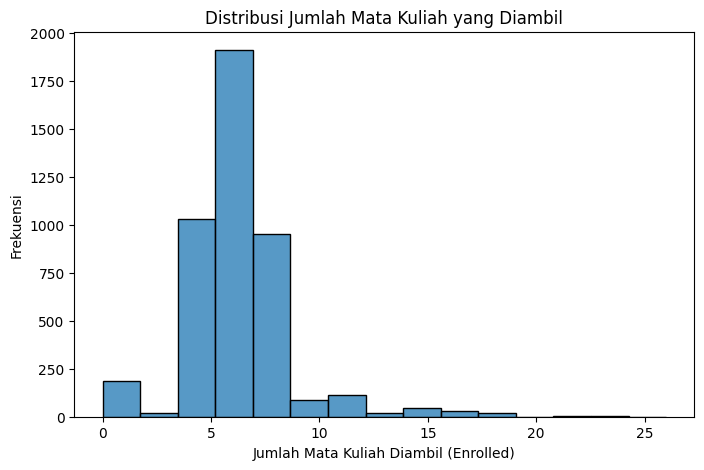

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(
    data[col_enrolled],
    bins=15
)

plt.title('Distribusi Jumlah Mata Kuliah yang Diambil')
plt.xlabel('Jumlah Mata Kuliah Diambil (Enrolled)')
plt.ylabel('Frekuensi')

plt.show()

## **8.2 Histogram Approved**

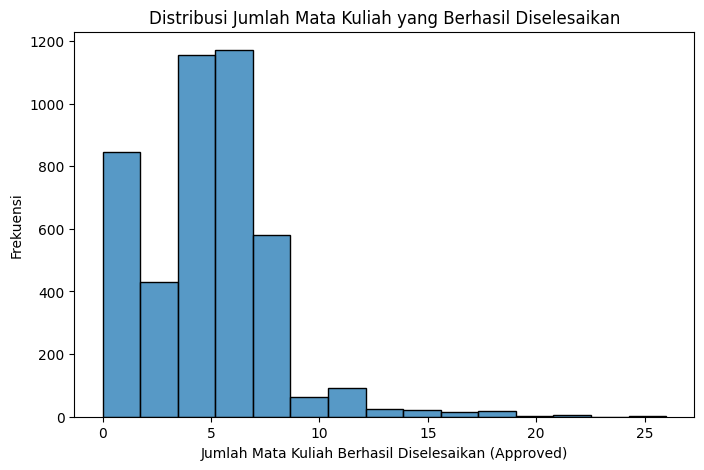

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(
    data[col_approved],
    bins=15
)

plt.title('Distribusi Jumlah Mata Kuliah yang Berhasil Diselesaikan')
plt.xlabel('Jumlah Mata Kuliah Berhasil Diselesaikan (Approved)')
plt.ylabel('Frekuensi')

plt.show()

## **8.3 Histogram Grade**

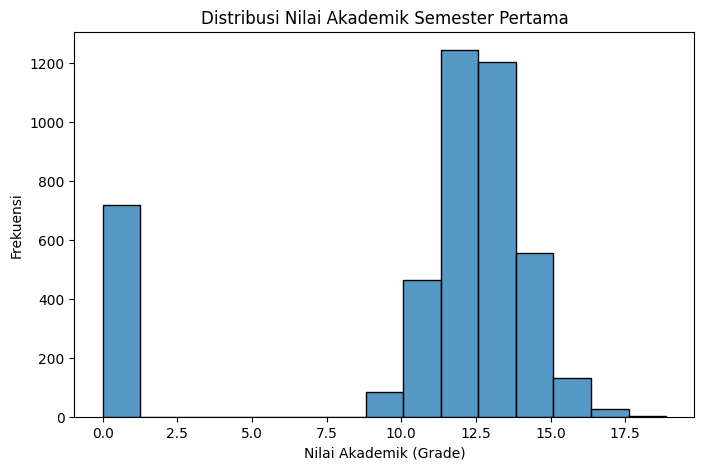

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(
    data[col_grade],
    bins=15
)

plt.title('Distribusi Nilai Akademik Semester Pertama')
plt.xlabel('Nilai Akademik (Grade)')
plt.ylabel('Frekuensi')

plt.show()